# 🚦 Road Accident Data Analysis & Visualization
**Dataset:** synthetic road accident records for 8 Tamil Nadu cities (2023–2024).

**Workflow**
1. Load the *original* (messy) CSV and inspect data quality problems
2. Clean the data and save `road_accidents_cleaned.csv`
3. Feature engineering (hour, weekday, age group, ...)
4. Exploratory analysis & visualizations
5. Key insights

## 1. Import libraries & load original data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

raw = pd.read_csv("road_accidents_original.csv")
print("Shape:", raw.shape)
raw.head(10)

Shape: (1560, 15)


,accident_id,date,time,city,road_type,weather,light_condition,vehicle_type,cause,severity,num_vehicles,num_casualties,driver_age,driver_gender,speed_limit
0,ACC100783,2023-03-31,18:45,Chennai,State Highway,CLEAR,Dusk/Dawn,Car,Over-speeding,Minor,3,2.0,22,M,80.0
1,ACC100197,28/03/2023,20:05,chennai,State Highway,Clear,Dark,truck,Over-speeding,serious,2,3.0,31,Female,60.0
2,ACC101051,24/09/2023,17:21,Trichy,National Highway,Clear,Daylight,Bus,Over-speeding,minor,2,2.0,NaN,Male,80.0
3,ACC100069,2023-12-09,09:12,Madurai,City Road,Clear,Daylight,Pedestrian Involved,Drunk Driving,Minor,4,1.0,48,Male,50.0
4,ACC101182,19/05/2024,19:22,Salem,National Highway,Rain,Dark,Truck,Over-speeding,Fatal,1,3.0,43,M,80.0
5,ACC100321,20/03/2023,17:40,Coimbatore,National Highway,clear,Daylight,Car,Over-speeding,Minor,4,1.0,32,F,NaN
6,ACC100896,2024-01-07,09:56,Coimbatore,State Highway,Cloudy,Daylight,Car,Wrong-Side Driving,Minor,4,2.0,38,Female,60.0
7,ACC100755,2023-11-16,14:20,Coimbatore,Rural Road,Clear,Daylight,Two-Wheeler,Drunk Driving,Minor,2,2.0,25,Male,60.0
8,ACC101336,10-Apr-2024,11:52,Chennai,Rural Road,Rain,Daylight,Bus,Distracted Driving,Serious,1,2.0,210,F,60.0
9,ACC100509,22/06/2023,23:16,Chennai,State Highway,Rain,Dark,Car,Over-speeding,Serious,1,2.0,38,Male,60.0


## 2. Data quality check (original data)

In [2]:
print("Duplicate accident_id rows :", raw.duplicated(subset="accident_id").sum())
print("Fully duplicated rows       :", raw.duplicated().sum())
print()
print("Missing values per column:")
print(raw.isna().sum())

Duplicate accident_id rows : 60
Fully duplicated rows       : 60

Missing values per column:
accident_id         0
date                0
time               49
city               16
road_type           0
weather            63
light_condition     0
vehicle_type        0
cause               0
severity            0
num_vehicles        0
num_casualties     63
driver_age         33
driver_gender      49
speed_limit        66
dtype: int64


In [3]:
# Inconsistent categorical labels (case / spaces / aliases)
for col in ["city", "weather", "severity", "driver_gender"]:
    print(col, "->", sorted(raw[col].dropna().astype(str).unique()))
    print()

city -> [' Chennai ', ' Coimbatore ', ' Erode ', ' Madurai ', ' Salem ', ' Tirunelveli ', ' Vellore ', 'CHENNAI', 'COIMBATORE', 'Chennai', 'Coimbatore', 'ERODE', 'Erode', 'MADURAI', 'Madurai', 'SALEM', 'Salem', 'TIRUNELVELI', 'Tiruchirappalli', 'Tirunelveli', 'Trichy', 'VELLORE', 'Vellore', 'chennai', 'coimbatore', 'erode', 'madurai', 'salem', 'tirunelveli', 'trichy', 'vellore']

weather -> [' Clear ', ' Cloudy ', ' Fog ', ' Rain ', 'CLEAR', 'CLOUDY', 'Clear', 'Cloudy', 'FOG', 'Fog', 'RAIN', 'Rain', 'clear', 'cloudy', 'fog', 'rain']

severity -> [' Fatal ', ' Minor ', ' Serious ', 'FATAL', 'Fatal', 'MINOR', 'Minor', 'SERIOUS', 'Serious', 'fatal', 'minor', 'serious']

driver_gender -> ['F', 'Female', 'M', 'Male']



In [4]:
# Invalid / suspicious numeric values
ages = pd.to_numeric(raw["driver_age"], errors="coerce")
cas  = pd.to_numeric(raw["num_casualties"], errors="coerce")
print("Non-numeric driver_age entries:", raw.loc[ages.isna() & raw["driver_age"].notna(), "driver_age"].unique())
print("Impossible ages (<16 or >90)  :", ((ages < 16) | (ages > 90)).sum())
print("Impossible casualties (<0 or >20):", ((cas < 0) | (cas > 20)).sum())
print("Date formats seen (samples)   :", raw["date"].sample(5, random_state=1).tolist())

Non-numeric driver_age entries: <StringArray>
['unknown']
Length: 1, dtype: str
Impossible ages (<16 or >90)  : 18
Impossible casualties (<0 or >20): 6
Date formats seen (samples)   : ['2023-02-05', '06-Feb-2024', '2024-02-27', '2023-01-31', '2023-10-28']


## 3. Data cleaning

In [5]:
df = raw.copy()

# 3.1 Remove duplicates
df = df.drop_duplicates().drop_duplicates(subset="accident_id").reset_index(drop=True)

# 3.2 Standardise text columns: trim spaces + consistent capitalisation
text_cols = ["city", "road_type", "weather", "vehicle_type", "severity", "cause", "driver_gender"]
for c in text_cols:
    df[c] = df[c].astype("string").str.strip().replace("", pd.NA)

df["city"] = df["city"].str.title().replace({"Trichy": "Tiruchirappalli"})
for c in ["road_type", "vehicle_type", "severity", "weather"]:
    df[c] = df[c].str.title()
df["road_type"] = df["road_type"].replace({"National Highway": "National Highway", "State Highway": "State Highway"})
df["vehicle_type"] = df["vehicle_type"].replace({"Two-Wheeler": "Two-Wheeler"})
df["driver_gender"] = df["driver_gender"].str.upper().replace({"M": "Male", "F": "Female", "MALE": "Male", "FEMALE": "Female"})
df["cause"] = df["cause"].replace({"Unknown": pd.NA})

# 3.3 Parse mixed date formats
def parse_date(x):
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y"):
        try:
            return pd.to_datetime(x, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT
df["date"] = df["date"].apply(parse_date)

# 3.4 Numeric columns: coerce junk -> NaN, then treat impossible values as NaN
for c in ["driver_age", "num_casualties", "speed_limit", "num_vehicles"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df.loc[(df["driver_age"] < 16) | (df["driver_age"] > 90), "driver_age"] = np.nan
df.loc[(df["num_casualties"] < 0) | (df["num_casualties"] > 20), "num_casualties"] = np.nan

# 3.5 Time: "N/A" -> NaN, then derive hour
df["time"] = df["time"].replace("N/A", pd.NA)
df["hour"] = pd.to_datetime(df["time"], format="%H:%M", errors="coerce").dt.hour

print("Rows after de-duplication:", len(df))

Rows after de-duplication: 1500


In [6]:
# 3.6 Impute missing values
df["driver_age"]      = df["driver_age"].fillna(df["driver_age"].median())
df["num_casualties"]  = df["num_casualties"].fillna(df.groupby("severity")["num_casualties"].transform("median"))
df["speed_limit"]     = df["speed_limit"].fillna(df.groupby("road_type")["speed_limit"].transform("median"))
for c in ["weather", "cause", "driver_gender", "city"]:
    df[c] = df[c].fillna("Unknown")

# hour missing -> infer from light condition (typical hour), otherwise overall median
typical_hour = df.groupby("light_condition")["hour"].median()
df["hour"] = df["hour"].fillna(df["light_condition"].map(typical_hour)).fillna(df["hour"].median()).astype(int)
df["time"] = df["time"].fillna(df["hour"].astype(str).str.zfill(2) + ":00")

# final dtypes
for c in ["driver_age", "num_casualties", "speed_limit", "num_vehicles"]:
    df[c] = df[c].round().astype(int)
for c in text_cols:
    df[c] = df[c].astype(str)

print("Missing values after cleaning:", int(df.isna().sum().sum()))

Missing values after cleaning: 0


## 4. Feature engineering

In [7]:
df["year"]       = df["date"].dt.year
df["month"]      = df["date"].dt.month
df["month_name"] = df["date"].dt.strftime("%b")
df["weekday"]    = df["date"].dt.day_name()
df["is_weekend"] = df["weekday"].isin(["Saturday", "Sunday"])
df["age_group"]  = pd.cut(df["driver_age"], bins=[15, 25, 35, 45, 55, 100],
                          labels=["16-25", "26-35", "36-45", "46-55", "56+"])
df["time_of_day"] = pd.cut(df["hour"], bins=[-1, 5, 11, 16, 20, 23],
                           labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-16)", "Evening (17-20)", "Late night (21-23)"])
df["severity"] = pd.Categorical(df["severity"], ["Minor", "Serious", "Fatal"], ordered=True)

df.to_csv("road_accidents_cleaned.csv", index=False)
print("Saved cleaned data:", df.shape)
df.head()

Saved cleaned data: (1500, 23)


,accident_id,date,time,city,road_type,weather,light_condition,vehicle_type,cause,severity,num_vehicles,num_casualties,driver_age,driver_gender,speed_limit,hour,year,month,month_name,weekday,is_weekend,age_group,time_of_day
0,ACC100783,2023-03-31,18:45,Chennai,State Highway,Clear,Dusk/Dawn,Car,Over-speeding,Minor,3,2,22,Male,80,18,2023,3,Mar,Friday,False,16-25,Evening (17-20)
1,ACC100197,2023-03-28,20:05,Chennai,State Highway,Clear,Dark,Truck,Over-speeding,Serious,2,3,31,Female,60,20,2023,3,Mar,Tuesday,False,26-35,Evening (17-20)
2,ACC101051,2023-09-24,17:21,Tiruchirappalli,National Highway,Clear,Daylight,Bus,Over-speeding,Minor,2,2,34,Male,80,17,2023,9,Sep,Sunday,True,26-35,Evening (17-20)
3,ACC100069,2023-12-09,09:12,Madurai,City Road,Clear,Daylight,Pedestrian Involved,Drunk Driving,Minor,4,1,48,Male,50,9,2023,12,Dec,Saturday,True,46-55,Morning (6-11)
4,ACC101182,2024-05-19,19:22,Salem,National Highway,Rain,Dark,Truck,Over-speeding,Fatal,1,3,43,Male,80,19,2024,5,May,Sunday,True,36-45,Evening (17-20)


In [8]:
df.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]].fillna("")

,count,unique,top,mean,min,max
accident_id,1500,1500,ACC100783,,,
date,1500,,,2024-01-03 22:41:16.800000,2023-01-01 00:00:00,2024-12-30 00:00:00
time,1500,856,12:00,,,
city,1500,9,Chennai,,,
road_type,1500,4,National Highway,,,
weather,1500,5,Clear,,,
light_condition,1500,3,Daylight,,,
vehicle_type,1500,6,Two-Wheeler,,,
cause,1500,7,Over-speeding,,,
severity,1500,3,Minor,,,


## 5. Exploratory analysis & visualizations

### 5.1 Overall severity distribution

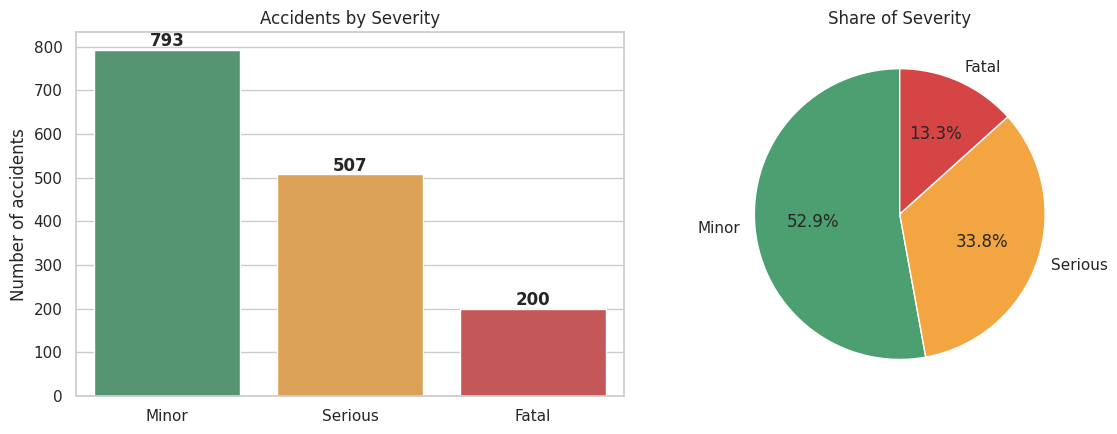

In [9]:
order = ["Minor", "Serious", "Fatal"]
colors = {"Minor": "#4C9F70", "Serious": "#F2A541", "Fatal": "#D64545"}
counts = df["severity"].value_counts().reindex(order)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=counts.index, y=counts.values, palette=colors, ax=ax[0])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 8, str(v), ha="center", fontweight="bold")
ax[0].set_title("Accidents by Severity"); ax[0].set_xlabel(""); ax[0].set_ylabel("Number of accidents")

ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
          colors=[colors[k] for k in order], wedgeprops={"edgecolor": "white"})
ax[1].set_title("Share of Severity")
plt.tight_layout(); plt.show()

### 5.2 Trend over time

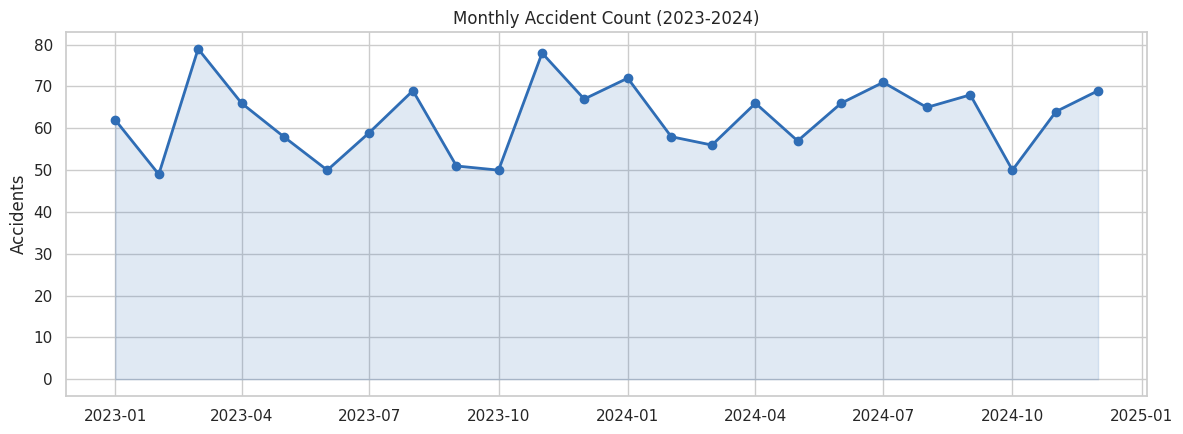

In [10]:
monthly = df.groupby(df["date"].dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly.values, marker="o", color="#2F6DB5", linewidth=2)
ax.fill_between(monthly.index, monthly.values, alpha=0.15, color="#2F6DB5")
ax.set_title("Monthly Accident Count (2023-2024)"); ax.set_ylabel("Accidents"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 5.3 When do accidents happen? (hour, weekday)

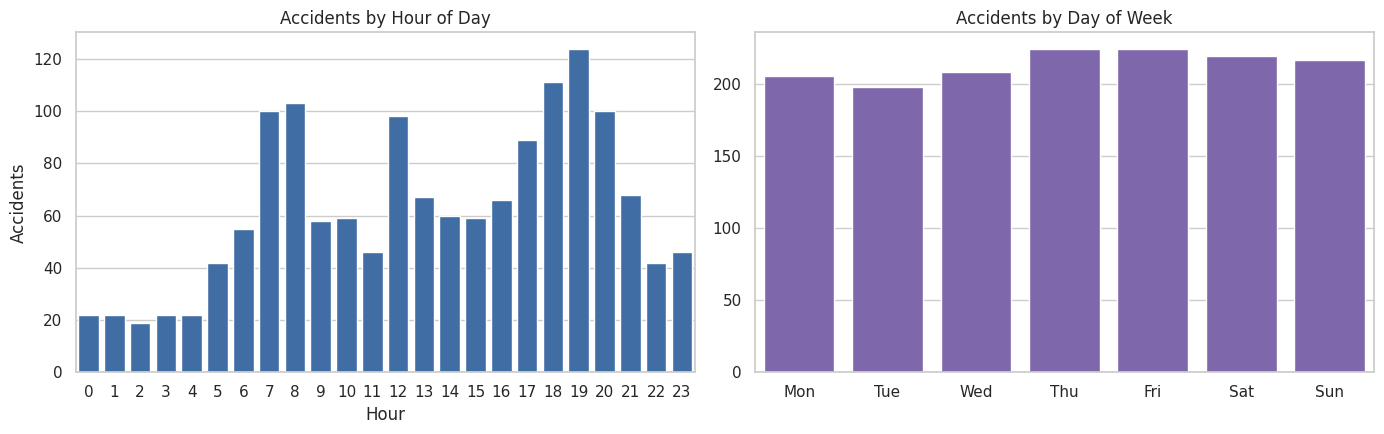

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

hourly = df["hour"].value_counts().sort_index()
sns.barplot(x=hourly.index, y=hourly.values, color="#2F6DB5", ax=ax[0])
ax[0].set_title("Accidents by Hour of Day"); ax[0].set_xlabel("Hour"); ax[0].set_ylabel("Accidents")

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = df["weekday"].value_counts().reindex(days)
sns.barplot(x=[d[:3] for d in days], y=wd.values, color="#7A5CB5", ax=ax[1])
ax[1].set_title("Accidents by Day of Week"); ax[1].set_xlabel(""); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

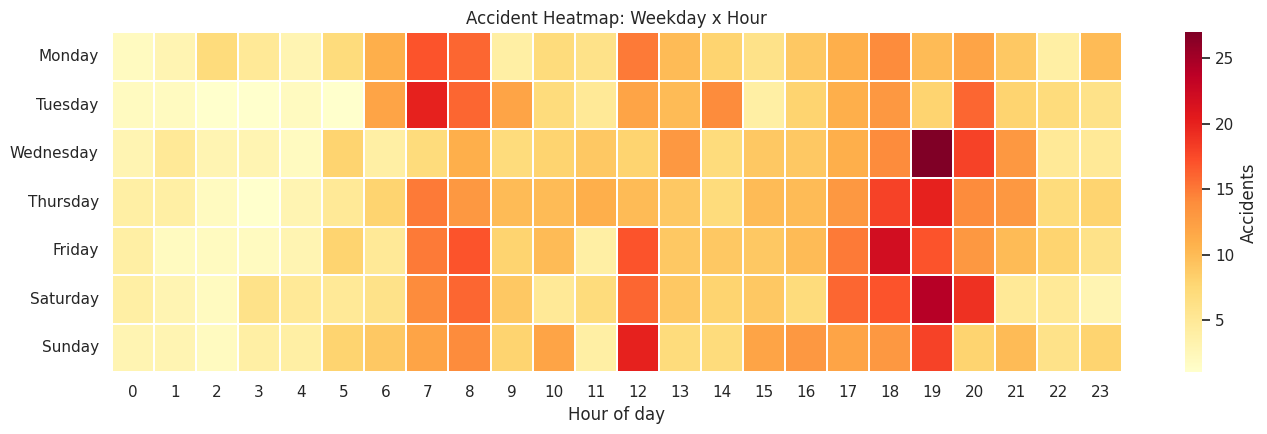

In [12]:
heat = df.pivot_table(index="weekday", columns="hour", values="accident_id", aggfunc="count", fill_value=0).reindex(days)
plt.figure(figsize=(14, 4.5))
sns.heatmap(heat, cmap="YlOrRd", linewidths=0.3, cbar_kws={"label": "Accidents"})
plt.title("Accident Heatmap: Weekday x Hour"); plt.xlabel("Hour of day"); plt.ylabel("")
plt.tight_layout(); plt.show()

### 5.4 City-wise analysis

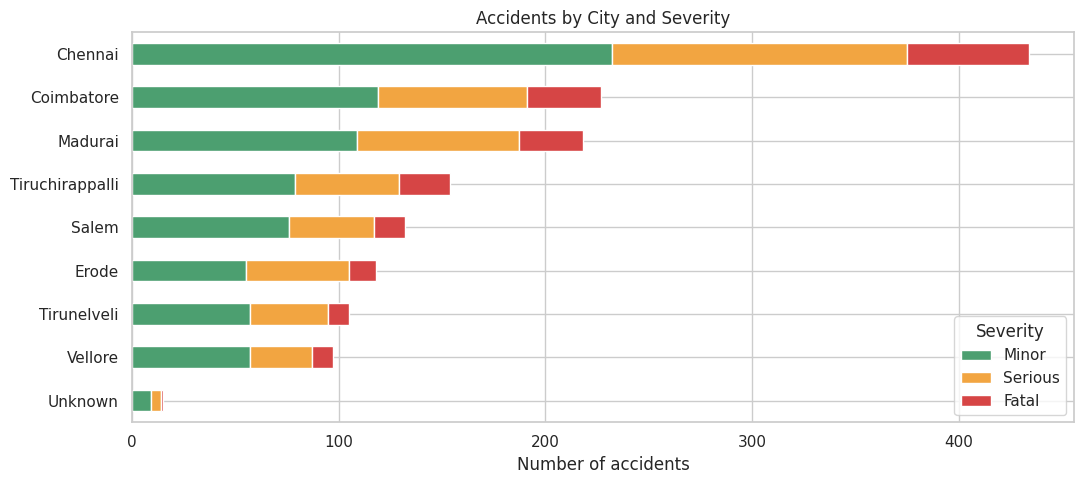

In [13]:
city_sev = pd.crosstab(df["city"], df["severity"])[order]
city_sev = city_sev.loc[city_sev.sum(axis=1).sort_values().index]
city_sev.plot(kind="barh", stacked=True, color=[colors[k] for k in order], figsize=(11, 5))
plt.title("Accidents by City and Severity"); plt.xlabel("Number of accidents"); plt.ylabel("")
plt.legend(title="Severity"); plt.tight_layout(); plt.show()

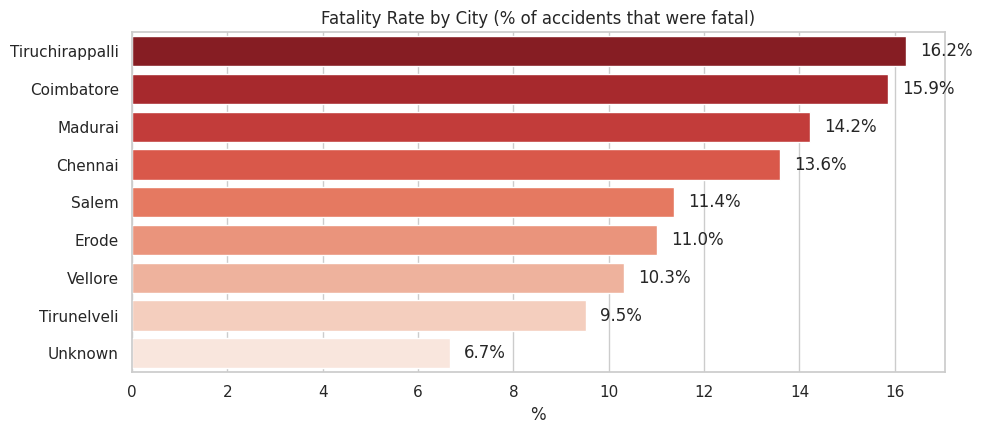

In [14]:
fatal_rate = (df.assign(fatal=df["severity"].eq("Fatal")).groupby("city")["fatal"].mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(10, 4.5))
sns.barplot(x=fatal_rate.values, y=fatal_rate.index, palette="Reds_r")
for i, v in enumerate(fatal_rate.values):
    plt.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.title("Fatality Rate by City (% of accidents that were fatal)"); plt.xlabel("%"); plt.ylabel("")
plt.tight_layout(); plt.show()

### 5.5 Causes, vehicles and road type

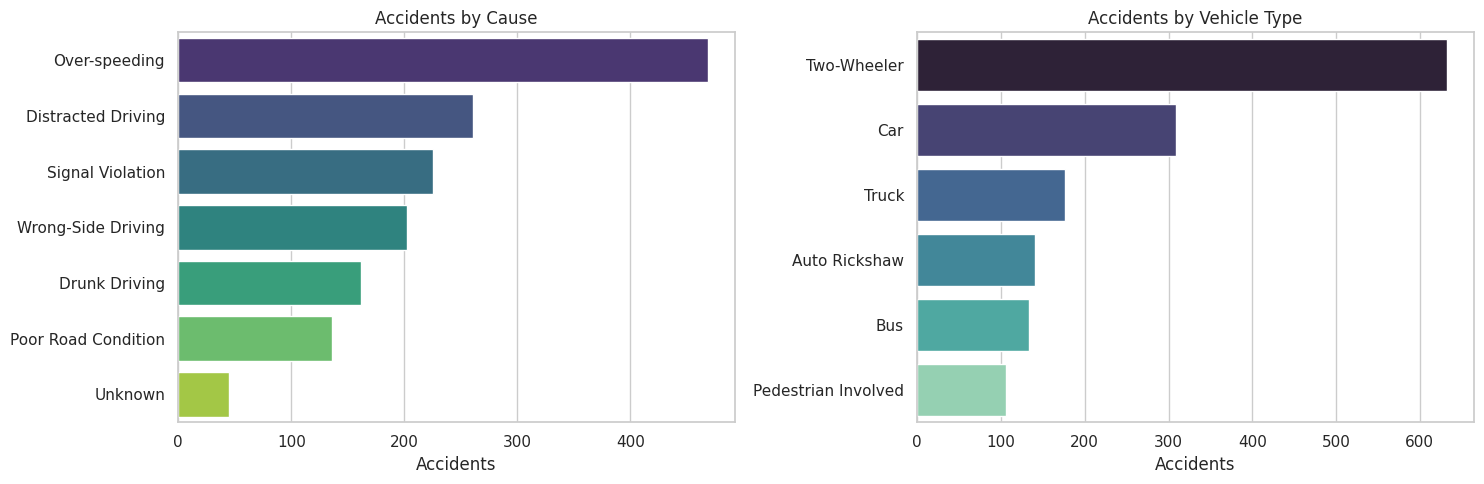

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

cause = df["cause"].value_counts()
sns.barplot(x=cause.values, y=cause.index, palette="viridis", ax=ax[0])
ax[0].set_title("Accidents by Cause"); ax[0].set_xlabel("Accidents"); ax[0].set_ylabel("")

veh = df["vehicle_type"].value_counts()
sns.barplot(x=veh.values, y=veh.index, palette="mako", ax=ax[1])
ax[1].set_title("Accidents by Vehicle Type"); ax[1].set_xlabel("Accidents"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

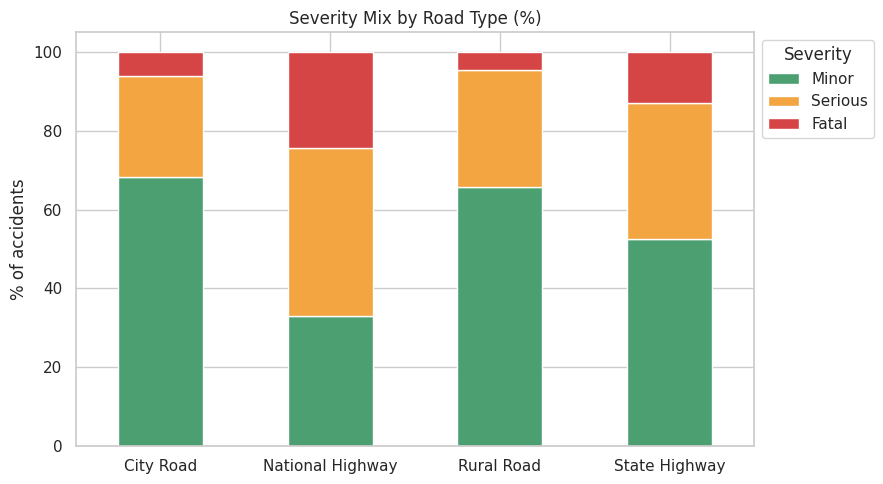

In [16]:
road_sev = pd.crosstab(df["road_type"], df["severity"], normalize="index")[order] * 100
road_sev.plot(kind="bar", stacked=True, color=[colors[k] for k in order], figsize=(9, 5))
plt.title("Severity Mix by Road Type (%)"); plt.ylabel("% of accidents"); plt.xlabel("")
plt.xticks(rotation=0); plt.legend(title="Severity", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

### 5.6 Weather & lighting conditions

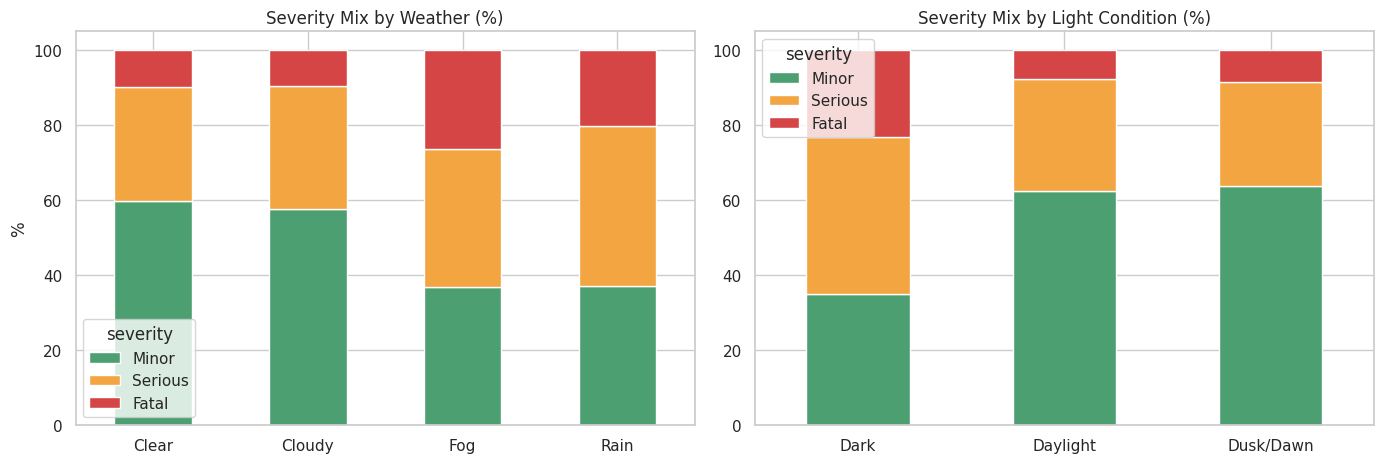

In [17]:
known = df[df["weather"] != "Unknown"]
w = pd.crosstab(known["weather"], known["severity"], normalize="index")[order] * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
w.plot(kind="bar", stacked=True, color=[colors[k] for k in order], ax=ax[0])
ax[0].set_title("Severity Mix by Weather (%)"); ax[0].set_ylabel("%"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)

l = pd.crosstab(df["light_condition"], df["severity"], normalize="index")[order] * 100
l.plot(kind="bar", stacked=True, color=[colors[k] for k in order], ax=ax[1])
ax[1].set_title("Severity Mix by Light Condition (%)"); ax[1].set_ylabel(""); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### 5.7 Driver profile

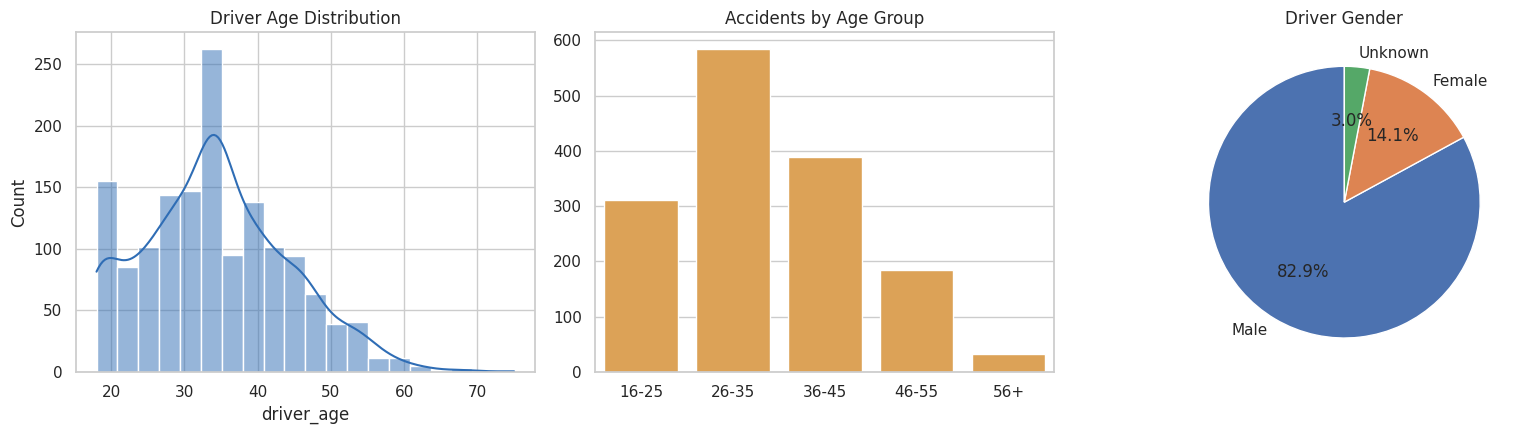

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df["driver_age"], bins=20, kde=True, color="#2F6DB5", ax=ax[0])
ax[0].set_title("Driver Age Distribution")

ag = df["age_group"].value_counts().sort_index()
sns.barplot(x=ag.index.astype(str), y=ag.values, color="#F2A541", ax=ax[1])
ax[1].set_title("Accidents by Age Group"); ax[1].set_xlabel(""); ax[1].set_ylabel("")

g = df["driver_gender"].value_counts()
ax[2].pie(g.values, labels=g.index, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "white"})
ax[2].set_title("Driver Gender")
plt.tight_layout(); plt.show()

### 5.8 Casualties & correlation

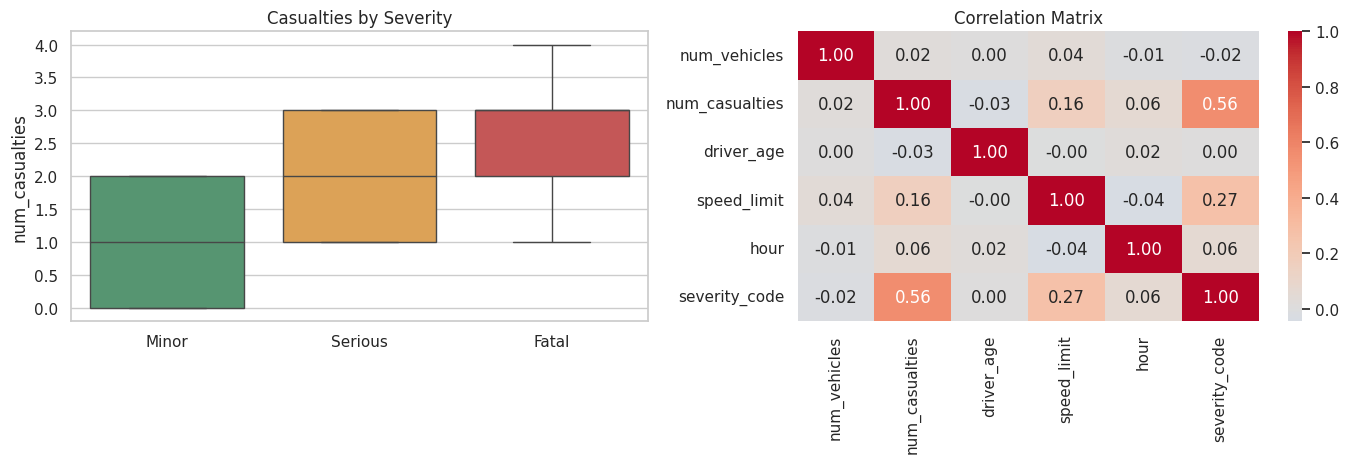

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=df, x="severity", y="num_casualties", order=order, palette=colors, ax=ax[0])
ax[0].set_title("Casualties by Severity"); ax[0].set_xlabel("")

num = df[["num_vehicles", "num_casualties", "driver_age", "speed_limit", "hour"]].copy()
num["severity_code"] = df["severity"].cat.codes
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Correlation Matrix")
plt.tight_layout(); plt.show()

## 6. Key insights

In [20]:
fatal_pct = (df["severity"] == "Fatal").mean() * 100
peak_hour = df["hour"].value_counts().idxmax()
top_cause = df["cause"].value_counts().idxmax()
top_vehicle = df["vehicle_type"].value_counts().idxmax()
top_city = df["city"].value_counts().idxmax()
night_fatal = (df.loc[df["light_condition"] == "Dark", "severity"] == "Fatal").mean() * 100
day_fatal   = (df.loc[df["light_condition"] == "Daylight", "severity"] == "Fatal").mean() * 100
nh_fatal    = (df.loc[df["road_type"] == "National Highway", "severity"] == "Fatal").mean() * 100

print(f"Total accidents analysed        : {len(df)}")
print(f"Total casualties                : {df['num_casualties'].sum()}")
print(f"Fatal accidents                 : {fatal_pct:.1f}%")
print(f"Peak hour                       : {peak_hour}:00")
print(f"Most common cause               : {top_cause}")
print(f"Most involved vehicle           : {top_vehicle}")
print(f"City with most accidents        : {top_city}")
print(f"Fatal share in darkness         : {night_fatal:.1f}%  vs daylight {day_fatal:.1f}%")
print(f"Fatal share on National Highways: {nh_fatal:.1f}%")

Total accidents analysed        : 1500
Total casualties                : 2333
Fatal accidents                 : 13.3%
Peak hour                       : 19:00
Most common cause               : Over-speeding
Most involved vehicle           : Two-Wheeler
City with most accidents        : Chennai
Fatal share in darkness         : 23.3%  vs daylight 7.8%
Fatal share on National Highways: 24.4%


**Takeaways (from this synthetic dataset)**
- Evening rush hours (17:00-20:00) have the most accidents.
- Two-wheelers are involved in the largest share of accidents.
- Over-speeding is the top cause, while drunk driving and over-speeding are linked to the most severe outcomes.
- Darkness, fog, rain and national highways all raise the share of fatal accidents.
- Drivers aged 26-35 are the most represented age group.

> ⚠️ The data is randomly generated for practice, so conclusions are illustrative only.